# ESMFold v1 — Sequence-support levels


## 1. Data source/acquisition

Download the released panel sequences, experimental residue mappings, model predictions and individual template-reference measurements. Query experimental PDB entries released by2020-05-01 and download the public PDB sequence file; record the exact response hashes. The date filter is fixed; source bytes are the retrieved public version. Use MMseqs2 15-6f452. Query the experimental method and resolution for every panel entry from the RCSB API; retain missing resolution explicitly.


In [1]:
from pathlib import Path
import os,json,hashlib,zipfile,urllib.request,io,socket
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display,Image
from Bio.SeqUtils import seq1
from tmtools import tm_align
DATA_ROOT=Path(os.environ.get('ESMFOLD_RELEASE_ROOT',str(Path.cwd()/'released-inputs')))
CALC_ROOT=Path(os.environ.get('ESMFOLD_CALC_ROOT',str(Path.cwd()/'calculations')))/'kimi-r1'
DATA_ROOT.mkdir(parents=True,exist_ok=True)
def sha256_file(path):
    digest=hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda:stream.read(1024*1024),b''):digest.update(block)
    return digest.hexdigest()
archive=DATA_ROOT/'esmfold2-inputs.zip'
source_url='https://github.com/shreyjain11/SPECTRAagent/releases/download/notebook-inputs-2026-11-08-v1/esmfold2-inputs.zip'
source_sha='c0c76766965d90de4128d0d3e11abadcf39f4acac8cff64c374657ee77172b24'
if not archive.is_file() or sha256_file(archive)!=source_sha:
    temporary=archive.with_suffix('.download')
    urllib.request.urlretrieve(source_url,temporary)
    if sha256_file(temporary)!=source_sha:raise ValueError('Public input archive fingerprint differs')
    temporary.replace(archive)
with zipfile.ZipFile(archive) as bundle:
    members=[m for m in bundle.infolist() if m.filename.startswith('assets/kimi-r1/') and not m.is_dir() and not m.filename.endswith('.py')]
    for item in members:
        destination=(DATA_ROOT/item.filename).resolve()
        if DATA_ROOT.resolve() not in destination.parents:raise ValueError('Invalid archive member path')
        destination.parent.mkdir(parents=True,exist_ok=True)
        payload=bundle.read(item)
        if not destination.exists() or hashlib.sha256(destination.read_bytes()).digest()!=hashlib.sha256(payload).digest():destination.write_bytes(payload)
P=DATA_ROOT/'assets/kimi-r1'
print('Verified public input archive:',source_url,'SHA256',source_sha)
print('Acquired data files:',len(members))

PANEL='discovery';RESULTS=P/'results';LEVELS=['A1', 'A2', 'A3', 'A4']


Verified public input archive: https://github.com/shreyjain11/SPECTRAagent/releases/download/notebook-inputs-2026-11-08-v1/esmfold2-inputs.zip SHA256 c0c76766965d90de4128d0d3e11abadcf39f4acac8cff64c374657ee77172b24
Acquired data files: 1508


In [2]:
import gzip,tarfile,subprocess,urllib.request,time
RAW=CALC_ROOT/'reference_source';RAW.mkdir(parents=True,exist_ok=True)
def acquire(url,path,expected=None):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True);receipt=path.with_suffix(path.suffix+'.source.json')
    if path.is_file() and receipt.is_file():
        known=json.loads(receipt.read_text())
        if sha256_file(path)!=known['sha256']:raise ValueError('Cached source bytes changed: '+str(path))
        if expected and known['sha256']!=expected:raise ValueError('Source fingerprint differs')
        return path
    temporary=path.with_suffix(path.suffix+'.partial')
    request=urllib.request.Request(url,headers={'User-Agent':'SPECTRA-protein-analysis/1.0'})
    with urllib.request.urlopen(request,timeout=180) as response,temporary.open('wb') as stream:
        headers={key:response.headers.get(key) for key in ['ETag','Last-Modified','Content-Length']}
        while True:
            block=response.read(1024*1024)
            if not block:break
            stream.write(block)
    digest=sha256_file(temporary)
    if expected and digest!=expected:raise ValueError('Downloaded source fingerprint differs')
    temporary.replace(path)
    record={'url':url,'sha256':digest,'bytes':path.stat().st_size,'headers':headers}
    receipt.write_text(json.dumps(record,indent=2));return path
def request_json(url,payload,name):
    path=RAW/(name+'.json');receipt=path.with_suffix('.receipt.json')
    query_sha=hashlib.sha256(json.dumps(payload,sort_keys=True).encode()).hexdigest()
    if path.exists() and receipt.exists():
        record=json.loads(receipt.read_text())
        if record['query_sha256']!=query_sha or record['response_sha256']!=sha256_file(path):raise ValueError('Cached API response binding differs')
        return json.loads(path.read_text())
    request=urllib.request.Request(url,data=json.dumps(payload).encode(),headers={'Content-Type':'application/json','User-Agent':'SPECTRA-protein-analysis/1.0'})
    for attempt in range(4):
        try:
            with urllib.request.urlopen(request,timeout=180) as response:data=json.load(response)
            break
        except Exception:
            if attempt==3:raise
            time.sleep(2)
    path.write_text(json.dumps(data));receipt.write_text(json.dumps({'url':url,'query_sha256':query_sha,'response_sha256':sha256_file(path)},indent=2))
    return data

reference_entries=[]
for start in range(0,500000,10000):
    payload={'query':{'type':'terminal','service':'text','parameters':{'attribute':'rcsb_accession_info.initial_release_date','operator':'less_or_equal','value':'2020-05-01T00:00:00Z'}},'return_type':'entry','request_options':{'paginate':{'start':start,'rows':10000}}}
    result=request_json('https://search.rcsb.org/rcsbsearch/v2/query',payload,f'precutoff_entries_{start:06}')
    reference_entries.extend(row['identifier'].upper() for row in result.get('result_set',[]))
    if start+10000>=result['total_count']:break
if len(reference_entries)<10000:raise ValueError('Incomplete reference-entry acquisition')
seqres_path=acquire('https://files.wwpdb.org/pub/pdb/derived_data/pdb_seqres.txt.gz',RAW/'pdb_seqres.txt.gz')
TOOLS=CALC_ROOT/'third_party';TOOLS.mkdir(parents=True,exist_ok=True)
MMSEQS=TOOLS/'mmseqs/bin/mmseqs'
if not MMSEQS.exists():
    archive=acquire('https://github.com/soedinglab/MMseqs2/releases/download/15-6f452/mmseqs-linux-avx2.tar.gz',TOOLS/'mmseqs15.tar.gz')
    with tarfile.open(archive,'r:gz') as bundle:bundle.extractall(TOOLS,filter='data')
print('Search version:',subprocess.check_output([str(MMSEQS),'version'],text=True).strip())
print('Experimental entries released by2020-05-01:',len(reference_entries))
panel_identifiers=pd.read_csv(RESULTS/'panel_final.tsv',sep='	',usecols=['rep'])
query_entries=sorted({rep.split('_')[0].upper() for rep in panel_identifiers.rep})
metadata_query='query($ids:[String!]!){entries(entry_ids:$ids){rcsb_id exptl{method} rcsb_entry_info{resolution_combined}}}'
entry_metadata=[]
for start in range(0,len(query_entries),50):
    response=request_json('https://data.rcsb.org/graphql',{'query':metadata_query,'variables':{'ids':query_entries[start:start+50]}},f'{PANEL}_experimental_metadata_{start:04}')
    if response.get('errors'):raise ValueError(response['errors'])
    entry_metadata.extend(row for row in response['data']['entries'] if row is not None)
missing_entries=sorted(set(query_entries)-{row['rcsb_id'].upper() for row in entry_metadata})
if missing_entries:
    from Bio.PDB.MMCIF2Dict import MMCIF2Dict
    for entry in missing_entries:
        path=acquire('https://files.rcsb.org/download/'+entry+'.cif.gz',RAW/(entry+'.cif.gz'))
        with gzip.open(path,'rt') as stream:fields=MMCIF2Dict(stream)
        values=fields.get('_refine.ls_d_res_high',fields.get('_em_3d_reconstruction.resolution',[]))
        resolutions=[float(value) for value in values if value not in ['?','.']]
        entry_metadata.append({'rcsb_id':entry,'rcsb_entry_info':{'resolution_combined':resolutions},'exptl':[{'method':value} for value in fields.get('_exptl.method',[])],'metadata_source':'public experimental mmCIF'})
if {row['rcsb_id'].upper() for row in entry_metadata}!=set(query_entries):raise ValueError('Missing experimental entry metadata')


Search version: 6f45232ac8daca14e354ae320a4359056ec524c2
Experimental entries released by2020-05-01: 163218


## 2. Data processing

Build the reference sequence database from pre-cutoff entry identifiers, retaining nonempty standard-amino-acid sequences. Read and validate every query sequence and experimental coordinate mapping from the released panel.


In [3]:
STD=set('ACDEFGHIKLMNPQRSTVWY');precutoff=set(reference_entries)
REFERENCE=CALC_ROOT/'precutoff_sequences.fasta';count=0
with gzip.open(seqres_path,'rt') as source,REFERENCE.open('w') as destination:
    header=None;parts=[]
    def write_sequence(header,parts):
        if header is None:return 0
        identifier=header.split()[0];entry=identifier.rsplit('_',1)[0].upper();sequence=''.join(parts).upper()
        if entry not in precutoff or not sequence or not set(sequence).issubset(STD):return 0
        destination.write('>'+identifier.upper().rsplit('_',1)[0]+'_'+identifier.rsplit('_',1)[1]+'\n'+sequence+'\n');return 1
    for line in source:
        if line.startswith('>'):count+=write_sequence(header,parts);header=line[1:].strip();parts=[]
        else:parts.append(line.strip())
    count+=write_sequence(header,parts)
if count<100000:raise ValueError('Reference sequence database unexpectedly small')
print('Reference chains:',count,'; sequence database SHA256:',sha256_file(REFERENCE))
plan=pd.read_csv(RESULTS/'panel_final.tsv',sep='\t',usecols=['rep'])
if plan.rep.duplicated().any():raise ValueError('Duplicate protein-chain IDs')
native_arrays={};rows=[]
for rep in plan.rep:
    path=RESULTS/'native'/f'{rep}.npz'
    with np.load(path) as source:
        sequence=str(source['seq']);indices=source['res_idx'].copy();coordinates=source['ca'].copy()
    if len(indices)!=len(coordinates) or len(indices)==0:raise ValueError('Invalid experimental residue mapping: '+rep)
    if indices.min()<0 or indices.max()>=len(sequence):raise ValueError('Experimental mapping lies outside the query')
    native_arrays[rep]=(sequence,indices,coordinates)
    rows.append({'rep':rep,'sequence':sequence,'sequence_length':len(sequence),'observed_residues':len(indices),'resolved_fraction':len(indices)/len(sequence),'native_sha256':sha256_file(path)})
features=pd.DataFrame(rows)
print('Processed full query sequences and experimental residue mappings:',len(features))
display(features[['rep','sequence_length','observed_residues','resolved_fraction']])

metadata_rows=[]
for entry in entry_metadata:
    resolution=(entry.get('rcsb_entry_info') or {}).get('resolution_combined') or []
    methods=entry.get('exptl') or []
    metadata_rows.append({'entry_id':entry['rcsb_id'].upper(),'resolution_angstrom':float(resolution[0]) if resolution else np.nan,'experimental_method':'; '.join(row['method'] for row in methods)})
features['entry_id']=features.rep.str.split('_').str[0].str.upper()
features=features.merge(pd.DataFrame(metadata_rows),on='entry_id',how='left',validate='many_to_one')
QUERY=CALC_ROOT/(PANEL+'_queries.fasta')
QUERY.write_text(''.join('>'+row.rep+'\n'+row.sequence+'\n' for row in features.itertuples()))


Reference chains: 524099 ; sequence database SHA256: e8111bbea699d0753f0d8e57c1cea1fa6a2521a70007e643926f3cb301ceaf96


Processed full query sequences and experimental residue mappings: 320


,rep,sequence_length,observed_residues,resolved_fraction
0,7SC4_A,130,111,0.853846
1,8BJP_AAA,112,109,0.973214
2,8BZN_A,125,124,0.992000
3,8DZ8_A,101,97,0.960396
4,8D51_A,103,99,0.961165
...,...,...,...,...
315,8T19_A,86,86,1.000000
316,7YHR_A,60,59,0.983333
317,8EB5_A,78,74,0.948718
318,8OKS_B,118,111,0.940678


67710

## 3. Axis definition and level construction

Search the pre-cutoff database at sensitivity7.5 with up to20 hits/query. Define support as the maximum sequence identity among hits covering at least50% of the query, or zero with no qualifying hit. Four levels use≥80%,50–80%,30–50%,<30%; the binary axis uses30%. Calculate12-residue low-complexity windows and three length strata directly.


In [4]:
import math
def lc_fraction(seq, win=12, thr=2.2):
    n = len(seq)
    if n < win:
        return 0.0
    mask = [0] * n
    for i in range(n - win + 1):
        w = seq[i:i + win]
        from collections import Counter
        c = Counter(w)
        H = -sum((v / win * math.log2(v / win) for v in c.values()))
        if H < thr:
            for j in range(i, i + win):
                mask[j] = 1
    return sum(mask) / n
search_path=CALC_ROOT/(PANEL+'_hits.tsv');search_receipt=search_path.with_suffix('.receipt.json')
binding={'query_sha256':sha256_file(QUERY),'reference_sha256':sha256_file(REFERENCE),'binary_sha256':sha256_file(MMSEQS),'sensitivity':7.5,'max_seqs':20,'coverage':.5}
if not search_path.exists() or not search_receipt.exists() or json.loads(search_receipt.read_text()).get('binding')!=binding:
    subprocess.run([str(MMSEQS),'easy-search',str(QUERY),str(REFERENCE),str(search_path),str(CALC_ROOT/(PANEL+'_search_tmp')),'-s','7.5','--max-seqs','20','-a','--format-output','query,target,pident,qstart,qend,qlen,tstart,tend,tlen,cigar','--threads','2','-v','1'],check=True)
    search_receipt.write_text(json.dumps({'binding':binding,'output_sha256':sha256_file(search_path)}))
if sha256_file(search_path)!=json.loads(search_receipt.read_text())['output_sha256']:raise ValueError('Search output fingerprint differs')
hits=pd.read_csv(search_path,sep='\t',header=None,names=['query','target','pident','qstart','qend','qlen','tstart','tend','tlen','cigar'])
hits['qcov']=(hits.qend-hits.qstart+1)/hits.qlen
eligible=hits[hits.qcov.ge(.5)]
best=eligible.sort_values('pident',ascending=False,kind='stable').drop_duplicates('query')
features=features.merge(best[['query','target','pident','qcov']].rename(columns={'query':'rep','target':'closest_reference','pident':'max_pident','qcov':'reference_coverage'}),on='rep',how='left',validate='one_to_one')
features['max_pident']=features.max_pident.fillna(0);features['reference_coverage']=features.reference_coverage.fillna(0)
features['level']=features.max_pident.map(lambda value:'A1' if value>=80 else 'A2' if value>=50 else 'A3' if value>=30 else 'A4')
features['group']=features.max_pident.map(lambda value:'nonorphan' if value>=30 else 'orphan')
features['length_bin']=pd.cut(features.sequence_length,[39,149,249,400],labels=['40–149','150–249','250–400'])
features['low_complexity_fraction']=features.sequence.map(lc_fraction)
display(features[['rep','sequence_length','max_pident','reference_coverage','level','group']])


,rep,sequence_length,max_pident,reference_coverage,level,group
0,7SC4_A,130,100.0,0.730769,A1,nonorphan
1,8BJP_AAA,112,99.1,1.000000,A1,nonorphan
2,8BZN_A,125,99.1,0.976000,A1,nonorphan
3,8DZ8_A,101,84.0,0.990099,A1,nonorphan
4,8D51_A,103,99.0,1.000000,A1,nonorphan
...,...,...,...,...,...,...
315,8T19_A,86,0.0,0.000000,A4,orphan
316,7YHR_A,60,0.0,0.000000,A4,orphan
317,8EB5_A,78,0.0,0.000000,A4,orphan
318,8OKS_B,118,0.0,0.000000,A4,orphan


## 4. Model results or released scores

Score the released ESMFold v1 coordinates against their experimental residue mappings with10 weighted-superposition iterations. Join individual released template-reference scores; their coverage is shown explicitly. The inference function is visible for an initialized fair-esm ESMFold v1 model. This run evaluates released model predictions. Compute mean Cα pLDDT directly from the confidence values in the prediction PDB files.


In [5]:
import numpy as np

def kabsch(P, Q, w=None):
    if w is None:
        w = np.ones(len(P))
    w = w / w.sum()
    cp = (P * w[:, None]).sum(0)
    cq = (Q * w[:, None]).sum(0)
    Pc = P - cp
    Qc = Q - cq
    H = (Pc * w[:, None]).T @ Qc
    U, S, Vt = np.linalg.svd(H)
    d = np.sign(np.linalg.det(Vt.T @ U.T))
    D = np.diag([1.0, 1.0, d])
    R = Vt.T @ D @ U.T
    return (R, cq - R @ cp)

def tm_gdt(P, Q, Lnorm):
    d0 = 1.24 * (max(Lnorm, 17) - 15) ** (1.0 / 3.0) - 1.8
    d0 = max(d0, 0.5)
    w = np.ones(len(P))
    for _ in range(10):
        R, t = kabsch(P, Q, w)
        d = np.linalg.norm(P @ R.T + t - Q, axis=1)
        w_new = 1.0 / (1.0 + (d / d0) ** 2)
        if np.allclose(w_new, w, atol=1e-06):
            w = w_new
            break
        w = w_new
    tm = float(np.mean(1.0 / (1.0 + (d / d0) ** 2))) * len(P) / Lnorm
    gdt_ts = float(np.mean([np.mean(d <= c) for c in (1, 2, 4, 8)])) * len(P) / Lnorm
    gdt_ha = float(np.mean([np.mean(d <= c) for c in (0.5, 1, 2, 4)])) * len(P) / Lnorm
    rmsd = float(np.sqrt(np.mean(d ** 2)))
    return (tm, gdt_ts, gdt_ha, rmsd)

def pred_ca(pdbpath):
    coords = []
    for line in open(pdbpath):
        if line.startswith('ATOM') and line[12:16].strip() == 'CA':
            coords.append([float(line[30:38]), float(line[38:46]), float(line[46:54])])
    return np.array(coords, dtype=np.float32)

def predict_structure(sequence,model,seed=0):
    import torch
    torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)
    with torch.no_grad():return model.infer_pdb(sequence)

score_rows=[]
for rep in features.rep:
    sequence,indices,native=native_arrays[rep]
    predicted=pred_ca(RESULTS/'pred'/f'{rep}.pdb')
    if len(predicted)!=len(sequence):raise ValueError('Prediction length does not match input sequence: '+rep)
    tm,gdt_ts,gdt_ha,rmsd=tm_gdt(predicted[indices],native,len(indices))
    confidence=[float(line[60:66]) for line in (RESULTS/'pred'/f'{rep}.pdb').read_text().splitlines() if line.startswith('ATOM') and line[12:16].strip()=='CA']
    if len(confidence)!=len(sequence) or not all(0<=value<=100 for value in confidence):raise ValueError('Invalid coordinate confidence values: '+rep)
    score_rows.append({'rep':rep,'mean_ca_plddt':float(np.mean(confidence)),'tm_model':float(f'{tm:.4f}'),'gdt_ts':float(f'{gdt_ts:.4f}'),'gdt_ha':float(f'{gdt_ha:.4f}'),'rmsd':float(f'{rmsd:.2f}')})
reference=pd.read_csv(RESULTS/'baseline_scores.tsv',sep='\t',usecols=['rep','baseline_tm','n_pairs','qcov'])
reference=reference.rename(columns={'baseline_tm':'tm_reference','n_pairs':'reference_pairs','qcov':'reference_query_coverage'})
measurements=features.merge(pd.DataFrame(score_rows),on='rep',validate='one_to_one').merge(reference,on='rep',how='left',validate='one_to_one')
if not np.isfinite(measurements.tm_model).all():raise ValueError('Incomplete target-model scores')
display(measurements[['rep','level','tm_model','gdt_ts','rmsd','tm_reference']])


,rep,level,tm_model,gdt_ts,rmsd,tm_reference
0,7SC4_A,A1,0.8530,0.8446,3.14,0.6995
1,8BJP_AAA,A1,0.9654,0.9656,0.76,0.8929
2,8BZN_A,A1,0.1725,0.0907,18.28,0.8714
3,8DZ8_A,A1,0.8349,0.8015,2.24,0.8362
4,8D51_A,A1,0.9077,0.8889,1.64,0.9471
...,...,...,...,...,...,...
315,8T19_A,A4,0.9407,0.9273,0.87,NaN
316,7YHR_A,A4,0.6179,0.6483,4.21,NaN
317,8EB5_A,A4,0.9076,0.9223,1.56,NaN
318,8OKS_B,A4,0.9371,0.9324,1.54,NaN


## 5. Curves and controls

Calculate Student-t mean intervals, explicit sample counts, length strata, composition, experimental resolution, confidence and resolved-fraction controls, and same-example model/reference means. Evaluate the stated trend or two-group test directly.


,level,model,n,mean,lo,hi
0,A1,ESMFold v1,80,0.867062,0.820603,0.913522
1,A1,Template reference,79,0.915280,0.889247,0.941313
2,A2,ESMFold v1,80,0.874430,0.834375,0.914485
3,A2,Template reference,80,0.833976,0.796968,0.870984
4,A3,ESMFold v1,80,0.909432,0.887416,0.931449
5,A3,Template reference,80,0.665528,0.624578,0.706477
6,A4,ESMFold v1,80,0.786431,0.734020,0.838843
7,A4,Template reference,10,0.589930,0.509316,0.670544


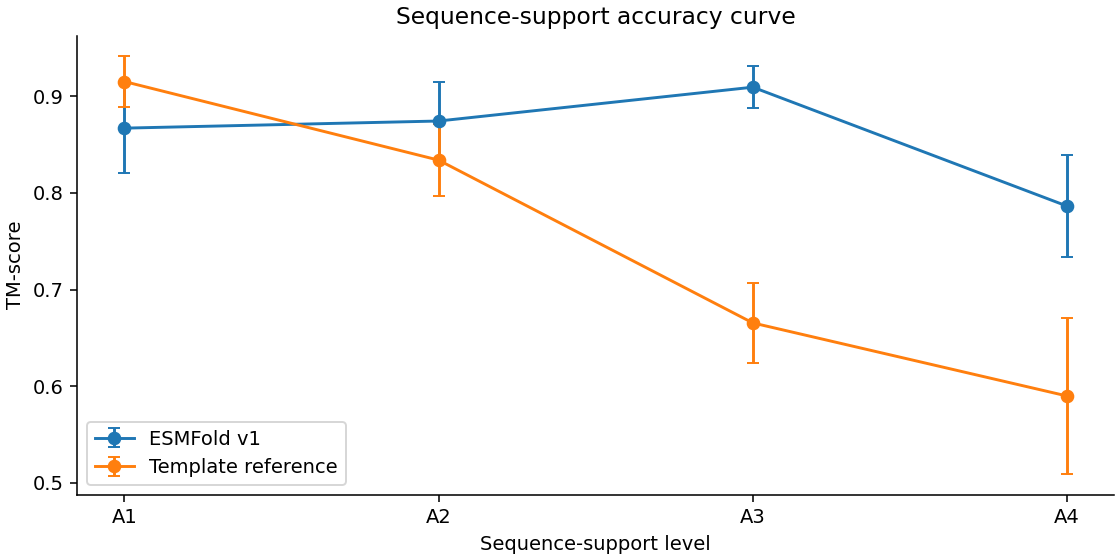

,n,mean_length,mean_resolved_fraction,mean_identity,mean_low_complexity,resolution_available,mean_resolution_angstrom,mean_ca_plddt,baseline_covered
level,,,,,,,,,
A1,80,202.8000,0.929259,98.07500,0.049580,80,1.959539,83.847588,79
A2,80,200.7375,0.930180,62.82625,0.041796,80,2.068734,83.233300,80
A3,80,204.8125,0.924715,38.86375,0.064511,80,1.967262,86.494426,80
A4,80,201.8000,0.934910,3.42125,0.060479,80,2.042928,79.123629,10


,level,length_bin,n,model_mean,reference_mean
0,A1,40–149,30,0.860447,0.883620
1,A1,150–249,24,0.852871,0.916165
2,A1,250–400,26,0.887796,0.951027
3,A2,40–149,32,0.856716,0.757981
4,A2,150–249,26,0.920388,0.876908
5,A2,250–400,22,0.845882,0.893777
6,A3,40–149,31,0.902239,0.640732
7,A3,150–249,25,0.906292,0.663528
8,A3,250–400,24,0.921996,0.699638
9,A4,40–149,31,0.776619,NaN


,n,model_mean,reference_mean
level,,,
A1,79,0.866346,0.915280
A2,80,0.874430,0.833976
A3,80,0.909432,0.665527
A4,10,0.795140,0.589930


In [6]:
def mean_curve(frame,column):
    records=[]
    for level,group in frame.groupby(column,observed=True):
        for label,metric in [('ESMFold v1','tm_model'),('Template reference','tm_reference')]:
            values=group[metric].dropna().to_numpy(float);n=len(values)
            if n==0:continue
            mean=float(values.mean());half=float(stats.t.ppf(.975,n-1)*stats.sem(values)) if n>1 else np.nan
            records.append({'level':str(level),'model':label,'n':n,'mean':mean,'lo':mean-half,'hi':mean+half})
    return pd.DataFrame(records)
column='level' if PANEL=='discovery' else 'group'
curves=mean_curve(measurements,column);display(curves)
fig,ax=plt.subplots(figsize=(8,4),layout='constrained')
for label,group in curves.groupby('model',sort=False):
    group=group.set_index('level').reindex(LEVELS).dropna(subset=['n']).reset_index()
    ax.errorbar(group.level,group['mean'],yerr=[group['mean']-group.lo,group.hi-group['mean']],marker='o',capsize=3,label=label)
ax.set(xlabel='Sequence-support level',ylabel='TM-score',title='Sequence-support accuracy curve');ax.legend();ax.spines[['top','right']].set_visible(False)
buffer=io.BytesIO();fig.savefig(buffer,format='png',dpi=140);plt.close(fig);display(Image(data=buffer.getvalue()))
confounds=measurements.groupby(column).agg(n=('rep','size'),mean_length=('sequence_length','mean'),mean_resolved_fraction=('resolved_fraction','mean'),mean_identity=('max_pident','mean'),mean_low_complexity=('low_complexity_fraction','mean'),resolution_available=('resolution_angstrom','count'),mean_resolution_angstrom=('resolution_angstrom','mean'),mean_ca_plddt=('mean_ca_plddt','mean'),baseline_covered=('tm_reference','count'))
length_controls=measurements.groupby([column,'length_bin'],observed=True).agg(n=('rep','size'),model_mean=('tm_model','mean'),reference_mean=('tm_reference','mean')).reset_index()
display(confounds);display(length_controls)
covered=measurements[measurements.tm_reference.notna()].copy()
covered_means=covered.groupby(column).agg(n=('rep','size'),model_mean=('tm_model','mean'),reference_mean=('tm_reference','mean'))
display(covered_means)


In [7]:
def jt_stat(groups):
    total=0.0
    for i in range(len(groups)):
        for j in range(i+1,len(groups)):
            difference=np.asarray(groups[i])[:,None]-np.asarray(groups[j])[None,:]
            total+=float((difference>0).sum()+.5*(difference==0).sum())
    return total
groups=[measurements.loc[measurements.level.eq(level),'tm_model'].to_numpy() for level in LEVELS]
if any(len(group)==0 for group in groups):raise ValueError('An identity level is empty; four-level trend cannot be evaluated')
observed=jt_stat(groups);pooled=np.concatenate(groups);sizes=np.array([len(group) for group in groups]);cuts=np.cumsum(sizes)[:-1];rng=np.random.default_rng(1);exceed=0
for _ in range(10000):exceed+=jt_stat(np.split(rng.permutation(pooled),cuts))>=observed
trend_p=(exceed+1)/10001
means=np.array([group.mean() for group in groups]);gap=float(means[0]-means[-1]);welch=stats.ttest_ind(groups[0],groups[-1],equal_var=False)
standardized=length_controls.pivot(index='length_bin',columns='level',values='model_mean').reindex(columns=LEVELS).dropna().mean()
coverage_levels=[level for level in LEVELS if level in covered_means.index and covered_means.loc[level,'n']>=20]
reference_diagnostic={}
if len(coverage_levels)>=2:
    first,last=coverage_levels[0],coverage_levels[-1]
    reference_diagnostic={'first':first,'last':last,'model_decline_on_covered':float(covered_means.loc[first,'model_mean']-covered_means.loc[last,'model_mean']),'reference_decline':float(covered_means.loc[first,'reference_mean']-covered_means.loc[last,'reference_mean'])}
statistics={'trend_p':trend_p,'trend_statistic':observed,'endpoint_gap':gap,'welch_p':float(welch.pvalue),'cohens_d':float(gap/np.sqrt((np.var(groups[0])+np.var(groups[-1]))/2)),'strictly_decreasing':bool(np.all(np.diff(means)<0)),'A1_mean_at_least_0_5':bool(means[0]>=.5),'length_standardized_means':standardized.to_dict(),'reference_diagnostic':reference_diagnostic}
display(statistics)
criteria=statistics['strictly_decreasing'] and gap>=.15 and trend_p<.01 and statistics['A1_mean_at_least_0_5']
decision=('Accept the sequence-support axis: ' if criteria else 'Reject the sequence-support axis under the stated criteria: ')+f"A1 mean={means[0]:.3f} (requires ≥0.5); decreasing means={statistics['strictly_decreasing']}; endpoint gap={gap:.3f} (requires ≥0.15); permutation p={trend_p:.5f} (requires <0.01)."


{'trend_p': 9.999000099990002e-05,
 'trend_statistic': 23045.5,
 'endpoint_gap': 0.08063125000000004,
 'welch_p': 0.023275738478794925,
 'cohens_d': 0.36460074774795936,
 'strictly_decreasing': False,
 'A1_mean_at_least_0_5': True,
 'length_standardized_means': {'A1': 0.8670378846153847,
  'A2': 0.8743286349067599,
  'A3': 0.9101755143369176,
  'A4': 0.7870897849462365},
 'reference_diagnostic': {'first': 'A1',
  'last': 'A3',
  'model_decline_on_covered': -0.04308693037974687,
  'reference_decline': 0.24975224683544317}}

## 6. What the agent decided, and why

Use the calculated curve, uncertainty, effect size and controls to state the supported conclusion.


In [8]:
print(decision)
output=CALC_ROOT/'test-01';output.mkdir(parents=True,exist_ok=True)
features.to_csv(output/'axis_levels.csv',index=False);measurements.to_csv(output/'coordinate_scores.csv',index=False);curves.to_csv(output/'curves.csv',index=False);confounds.to_csv(output/'confounds.csv');length_controls.to_csv(output/'length_controls.csv',index=False)
(output/'statistics.json').write_text(json.dumps(statistics,indent=2))
receipt={'analysis_id':'esmfold2-kimi-r1/test-01','completed':True,'host':socket.gethostname(),'targets':len(features),'new_inference_executed':False,'input_archive_sha256':source_sha,'reference_sequences_sha256':sha256_file(REFERENCE),'search_binding':binding,'search_output_sha256':sha256_file(search_path),'decision':decision}
(output/'CALCULATION_RECEIPT.json').write_text(json.dumps(receipt,indent=2))


Reject the sequence-support axis under the stated criteria: A1 mean=0.867 (requires ≥0.5); decreasing means=False; endpoint gap=0.081 (requires ≥0.15); permutation p=0.00010 (requires <0.01).


1029